# HVAC Predictive Maintenance – Mini Project

**Objective:** Predict whether an HVAC system is likely to fail using sensor readings.


## 1. Import the required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, classification_report
)

%matplotlib inline

## 2. Create a synthetic HVAC dataset

Each row represents one observation of an HVAC system. `Failure` is the target column: 0 means normal and 1 means failure.

In [2]:
np.random.seed(42)

data = {
    'Temperature': np.random.uniform(18, 45, 1000),
    'Humidity': np.random.uniform(25, 80, 1000),
    'Vibration': np.random.uniform(1, 10, 1000),
    'Pressure': np.random.uniform(20, 40, 1000),
    'Energy_Consumption': np.random.uniform(2, 15, 1000),
    'Runtime_Hours': np.random.uniform(100, 10000, 1000)
}

df = pd.DataFrame(data)

                                          
warning_conditions = (
    (df['Temperature'] > 35).astype(int) +
    (df['Vibration'] > 6).astype(int) +
    (df['Pressure'] < 25).astype(int) +
    (df['Runtime_Hours'] > 7000).astype(int)
)

                                                          
df['Failure'] = (warning_conditions >= 2).astype(int)

                                                     
df.loc[10, 'Temperature'] = np.nan
df.loc[25, 'Humidity'] = np.nan
df.loc[40, 'Pressure'] = np.nan

                                                                
df.loc[50, 'Vibration'] = 25
df.loc[60, 'Temperature'] = 100

                                     
df.to_csv('hvac_dataset.csv', index=False)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset created successfully!
Dataset shape: (1000, 7)


,Temperature,Humidity,Vibration,Pressure,Energy_Consumption,Runtime_Hours,Failure
0,28.112583,35.182311,3.355351,33.454060,9.435946,3996.991651,0
1,43.669286,54.804552,3.222809,35.933628,12.470620,4787.013028,0
2,37.763836,73.012021,9.156291,25.009358,11.882092,8560.019193,1
3,34.163779,65.272369,3.245916,32.497482,4.000699,3466.043422,0
4,22.212503,69.360863,3.447548,31.434920,3.940243,8709.531880,0


## 3. Understand the dataset

### 3.1 Dataset size and column names

In [3]:
print("Rows and columns:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

Rows and columns: (1000, 7)

Column names:
['Temperature', 'Humidity', 'Vibration', 'Pressure', 'Energy_Consumption', 'Runtime_Hours', 'Failure']


### 3.2 Data types and non-missing values

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Temperature         999 non-null    float64
 1   Humidity            999 non-null    float64
 2   Vibration           1000 non-null   float64
 3   Pressure            999 non-null    float64
 4   Energy_Consumption  1000 non-null   float64
 5   Runtime_Hours       1000 non-null   float64
 6   Failure             1000 non-null   int64  
dtypes: float64(6), int64(1)
memory usage: 54.8 KB


### 3.3 Summary statistics

In [5]:
df.describe()

,Temperature,Humidity,Vibration,Pressure,Energy_Consumption,Runtime_Hours,Failure
count,999.000000,999.000000,1000.000000,999.000000,1000.000000,1000.000000,1000.000000
mean,31.321198,52.887758,5.541527,29.813727,8.423369,5034.798443,0.401000
std,8.175595,16.078392,2.687572,5.729271,3.728529,2863.028585,0.490346
min,18.125065,25.177004,1.000105,20.013068,2.000399,161.219844,0.000000
25%,24.405424,38.252090,3.352159,24.854188,5.184662,2568.862043,0.000000
50%,31.455930,53.548288,5.516687,29.690760,8.429775,4954.987872,0.000000
75%,38.135039,66.835216,7.838206,34.753111,11.619915,7424.532604,1.000000
max,100.000000,79.967755,25.000000,39.991154,14.970742,9993.567975,1.000000


### 3.4 Missing values

In [6]:
print(df.isnull().sum())

Temperature           1
Humidity              1
Vibration             0
Pressure              1
Energy_Consumption    0
Runtime_Hours         0
Failure               0
dtype: int64


### 3.5 Duplicate records

In [7]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


### 3.6 Normal and failure records

Failure
0    599
1    401
Name: count, dtype: int64


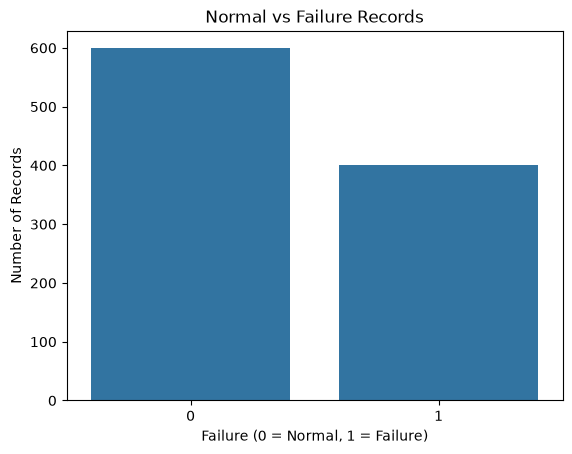

In [8]:
print(df['Failure'].value_counts())

sns.countplot(data=df, x='Failure')
plt.title('Normal vs Failure Records')
plt.xlabel('Failure (0 = Normal, 1 = Failure)')
plt.ylabel('Number of Records')
plt.show()

## 4. Data preprocessing

In this section:
- Fill missing numerical values using the median.
- Detect and cap extreme values using the IQR method.
- Separate input features (`X`) from the target (`y`).

We will fit the imputer and outlier limits using the training data only, to avoid using test data information during training.

### 4.1 Separate features and target

In [9]:
X = df.drop('Failure', axis=1)
y = df['Failure']

print("Input features shape:", X.shape)
print("Target shape:", y.shape)

Input features shape: (1000, 6)
Target shape: (1000,)


### 4.2 Split into training and testing data

The training set is used to teach the model. The test set is used to check how well it performs on data it has not seen.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 800
Testing rows: 200


### 4.3 Handle missing values

We use the median of each training column to fill missing values. The same training medians are then applied to the test data.

In [11]:
imputer = SimpleImputer(strategy='median')

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

print("Missing values in training data:")
print(X_train_imputed.isnull().sum())
print("\nMissing values in testing data:")
print(X_test_imputed.isnull().sum())

Missing values in training data:
Temperature           0
Humidity              0
Vibration             0
Pressure              0
Energy_Consumption    0
Runtime_Hours         0
dtype: int64

Missing values in testing data:
Temperature           0
Humidity              0
Vibration             0
Pressure              0
Energy_Consumption    0
Runtime_Hours         0
dtype: int64


### 4.4 Detect and handle outliers using IQR

IQR means Interquartile Range. Values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR are treated as extreme. We cap them at these limits instead of deleting rows.

In [12]:
def cap_outliers(train_data, test_data):
    train_data = train_data.copy()
    test_data = test_data.copy()
    limits = {}

    for column in train_data.columns:
        q1 = train_data[column].quantile(0.25)
        q3 = train_data[column].quantile(0.75)
        iqr = q3 - q1

        lower_limit = q1 - 1.5 * iqr
        upper_limit = q3 + 1.5 * iqr
        limits[column] = (lower_limit, upper_limit)

        train_data[column] = train_data[column].clip(lower_limit, upper_limit)
        test_data[column] = test_data[column].clip(lower_limit, upper_limit)

    return train_data, test_data, limits

X_train_clean, X_test_clean, outlier_limits = cap_outliers(
    X_train_imputed, X_test_imputed
)

print("Outlier handling completed.")
display(X_train_clean.head())

Outlier handling completed.


,Temperature,Humidity,Vibration,Pressure,Energy_Consumption,Runtime_Hours
747,32.675927,39.289726,2.322664,28.223950,2.506452,9801.558929
899,20.308730,68.108548,1.338140,36.893318,13.840741,5377.247372
175,22.707894,54.699196,8.533370,23.712934,14.942396,8184.886908
970,35.919121,26.330547,4.424659,39.476008,8.176304,7933.976072
686,33.433543,75.751645,2.119316,38.582894,3.810303,5056.133370


## 5. Exploratory Data Analysis (EDA)

EDA helps us understand the sensor readings and look for patterns related to failure. The graphs below use the original data; missing values are automatically ignored by these plots.

### 5.1 Failure count

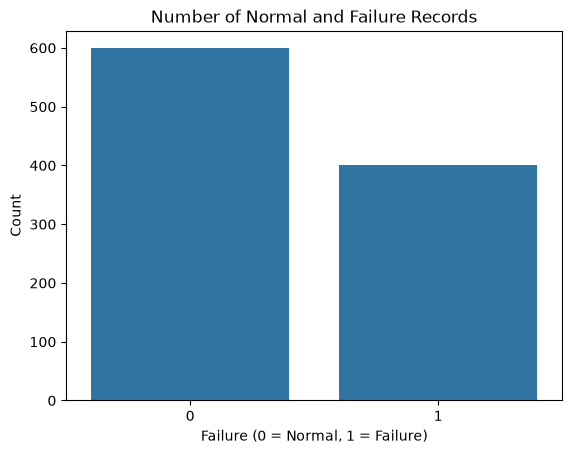

In [13]:
sns.countplot(data=df, x='Failure')
plt.title('Number of Normal and Failure Records')
plt.xlabel('Failure (0 = Normal, 1 = Failure)')
plt.ylabel('Count')
plt.show()

### 5.2 Temperature compared with failure

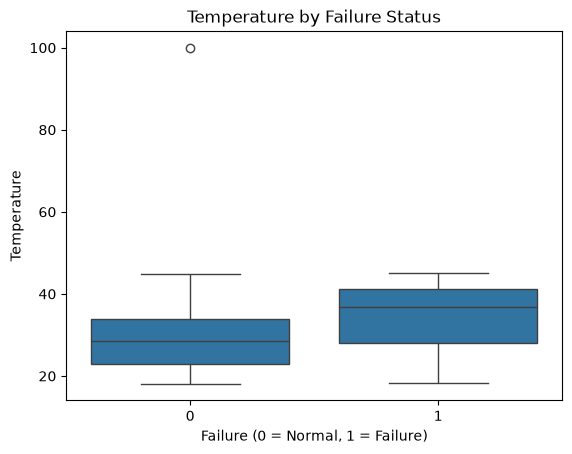

In [14]:
sns.boxplot(data=df, x='Failure', y='Temperature')
plt.title('Temperature by Failure Status')
plt.xlabel('Failure (0 = Normal, 1 = Failure)')
plt.ylabel('Temperature')
plt.show()

### 5.3 Vibration compared with failure

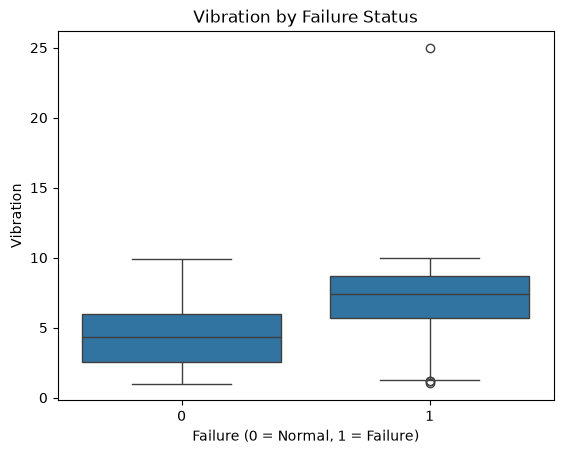

In [15]:
sns.boxplot(data=df, x='Failure', y='Vibration')
plt.title('Vibration by Failure Status')
plt.xlabel('Failure (0 = Normal, 1 = Failure)')
plt.ylabel('Vibration')
plt.show()

### 5.4 Correlation between numerical columns

Correlation shows how strongly two numerical columns move together. Values closer to 1 or -1 indicate stronger relationships; values near 0 indicate weaker linear relationships.

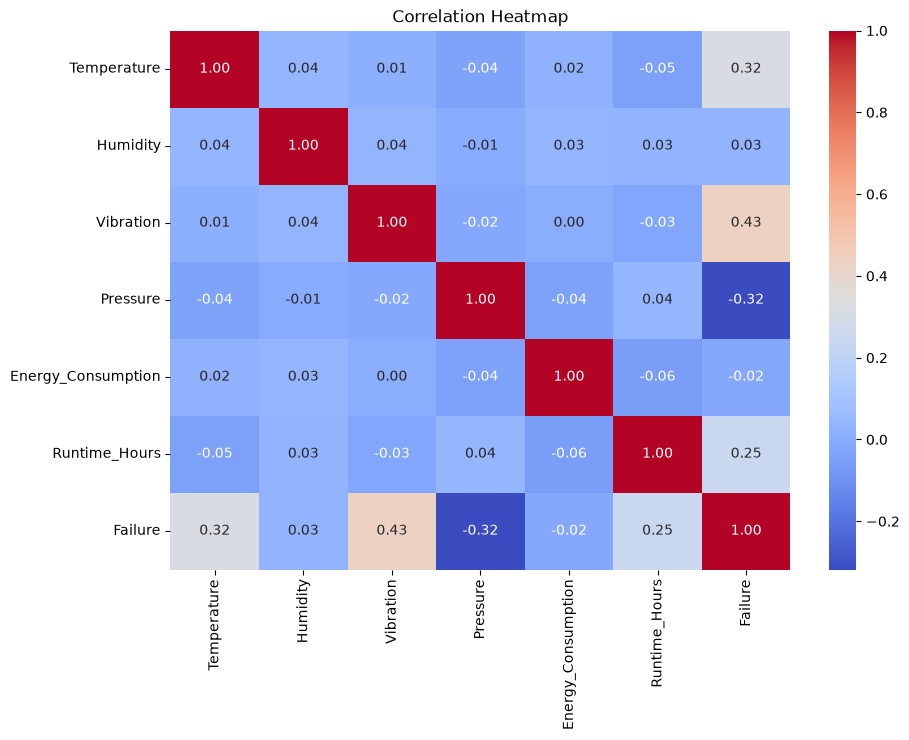

In [16]:
plt.figure(figsize=(10, 7))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## 6. Feature engineering

Feature engineering means creating useful new columns from existing columns. We will create two simple features:
- `High_Temperature`: 1 when temperature is above 35, otherwise 0.
- `High_Vibration`: 1 when vibration is above 6, otherwise 0.

These are simple example thresholds used for this synthetic dataset.

In [17]:
def add_features(data):
    data = data.copy()
    data['High_Temperature'] = (data['Temperature'] > 35).astype(int)
    data['High_Vibration'] = (data['Vibration'] > 6).astype(int)
    return data

X_train_features = add_features(X_train_clean)
X_test_features = add_features(X_test_clean)

print("New features added:")
display(X_train_features.head())

New features added:


,Temperature,Humidity,Vibration,Pressure,Energy_Consumption,Runtime_Hours,High_Temperature,High_Vibration
747,32.675927,39.289726,2.322664,28.223950,2.506452,9801.558929,0,0
899,20.308730,68.108548,1.338140,36.893318,13.840741,5377.247372,0,0
175,22.707894,54.699196,8.533370,23.712934,14.942396,8184.886908,0,1
970,35.919121,26.330547,4.424659,39.476008,8.176304,7933.976072,1,0
686,33.433543,75.751645,2.119316,38.582894,3.810303,5056.133370,0,0


## 7. Feature scaling

Scaling puts numerical features on a similar scale. It is useful for Logistic Regression. We fit the scaler using training data and apply it to both training and test data.

In [18]:
scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_features),
    columns=X_train_features.columns,
    index=X_train_features.index
)

X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_features),
    columns=X_test_features.columns,
    index=X_test_features.index
)

display(X_train_scaled.head())

,Temperature,Humidity,Vibration,Pressure,Energy_Consumption,Runtime_Hours,High_Temperature,High_Vibration
747,0.152166,-0.842201,-1.221924,-0.269056,-1.589577,1.689543,-0.752036,-0.879679
899,-1.433872,0.954121,-1.600625,1.235684,1.452450,0.129238,-0.752036,-0.879679
175,-1.126190,0.118295,1.167044,-1.052032,1.748124,1.119398,-0.752036,1.136778
970,0.568091,-1.649967,-0.413385,1.683960,-0.067837,1.030910,1.329724,-0.879679
686,0.249327,1.430527,-1.300143,1.528943,-1.239634,0.015992,-0.752036,-0.879679


## 8. Model development

We will train two models and compare their results:
1. Logistic Regression – a simple classification model.
2. Random Forest – a model that combines multiple decision trees.

The target values are 0 (normal) and 1 (failure).

### 8.1 Train Logistic Regression

In [19]:
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train_scaled, y_train)

logistic_predictions = logistic_model.predict(X_test_scaled)
logistic_probabilities = logistic_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression training completed.")

Logistic Regression training completed.


### 8.2 Train Random Forest

In [20]:
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

random_forest_model.fit(X_train_features, y_train)

rf_predictions = random_forest_model.predict(X_test_features)
rf_probabilities = random_forest_model.predict_proba(X_test_features)[:, 1]

print("Random Forest training completed.")

Random Forest training completed.


## 9. Model evaluation

We will compare the models using the metrics requested in the assignment:
- **Accuracy:** Overall proportion of correct predictions.
- **Precision:** Of the records predicted as failure, how many were actually failures?
- **Recall:** Of the actual failures, how many did the model identify?
- **F1-score:** Balance between precision and recall.
- **ROC-AUC:** How well the model separates the two classes.

In [21]:
def evaluate_model(model_name, actual, predicted, probabilities):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(actual, predicted),
        'Precision': precision_score(actual, predicted, zero_division=0),
        'Recall': recall_score(actual, predicted, zero_division=0),
        'F1-score': f1_score(actual, predicted, zero_division=0),
        'ROC-AUC': roc_auc_score(actual, probabilities)
    }

results = pd.DataFrame([
    evaluate_model('Logistic Regression', y_test, logistic_predictions, logistic_probabilities),
    evaluate_model('Random Forest', y_test, rf_predictions, rf_probabilities)
])

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.925,0.892,0.925,0.908,0.981
1,Random Forest,1.000,1.000,1.000,1.000,1.000


## 10. Confusion matrices

A confusion matrix shows correct and incorrect predictions for each class.

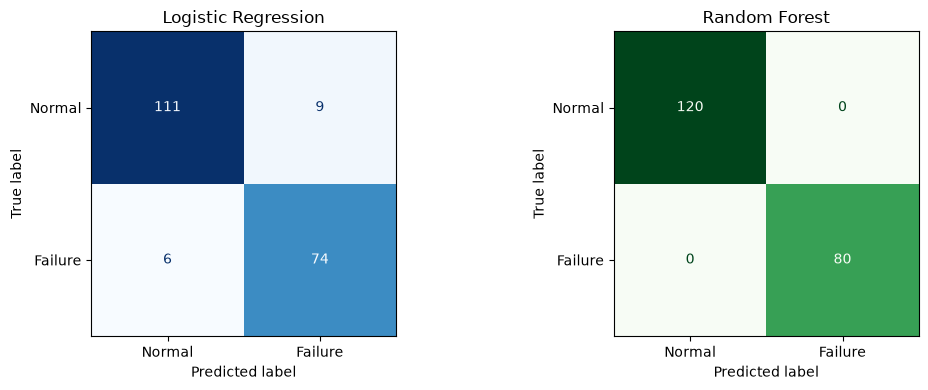

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test, logistic_predictions,
    display_labels=['Normal', 'Failure'],
    cmap='Blues', ax=axes[0], colorbar=False
)
axes[0].set_title('Logistic Regression')

ConfusionMatrixDisplay.from_predictions(
    y_test, rf_predictions,
    display_labels=['Normal', 'Failure'],
    cmap='Greens', ax=axes[1], colorbar=False
)
axes[1].set_title('Random Forest')

plt.tight_layout()
plt.show()

## 11. ROC curve

The ROC curve shows how well a model distinguishes normal records from failure records. A curve closer to the top-left generally indicates better classification.

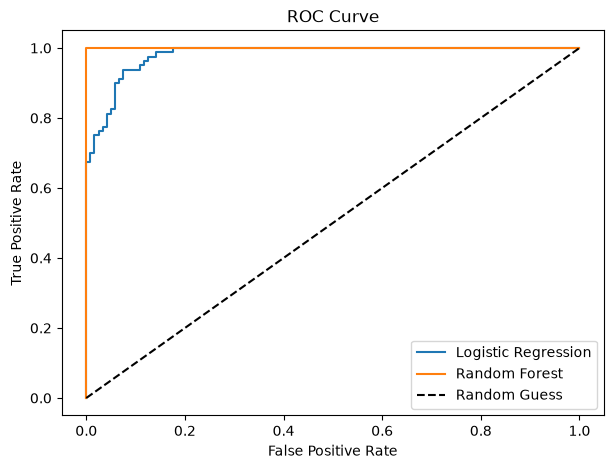

In [23]:
logistic_fpr, logistic_tpr, _ = roc_curve(y_test, logistic_probabilities)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(logistic_fpr, logistic_tpr, label='Logistic Regression')
plt.plot(rf_fpr, rf_tpr, label='Random Forest')
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

## 12. Feature importance

Random Forest can estimate how useful each input feature was for its predictions. Higher importance means the feature contributed more to the model's decisions. This is not proof that the feature causes a real HVAC failure.

,Feature,Importance
3,Pressure,0.221743
5,Runtime_Hours,0.185081
2,Vibration,0.174169
0,Temperature,0.144059
6,High_Temperature,0.105391
7,High_Vibration,0.104363
1,Humidity,0.033155
4,Energy_Consumption,0.032038


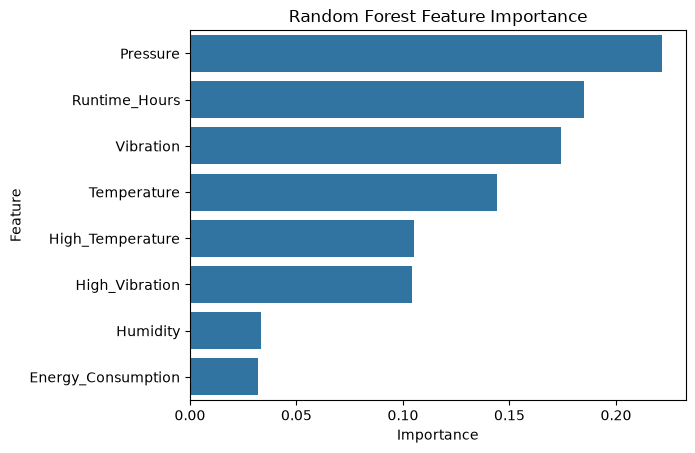

In [24]:
importance = pd.DataFrame({
    'Feature': X_train_features.columns,
    'Importance': random_forest_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

display(importance)

sns.barplot(data=importance, x='Importance', y='Feature')
plt.title('Random Forest Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

## 13. Conclusion and recommendations

Run the cells above first, then complete this section using your actual model results.

### Conclusion
This mini project used HVAC sensor readings such as temperature, humidity, vibration, pressure, energy consumption and runtime hours to predict whether a record was normal or marked as a failure. A synthetic dataset was created for this exercise. Missing values were filled using the median, extreme values were capped using the IQR method, and simple graphs were used to explore the data. Logistic Regression and Random Forest were trained and compared using accuracy, precision, recall, F1-score and ROC-AUC.

### Recommendations
- Monitor temperature and vibration readings regularly.
- Investigate unusual sensor readings before equipment failure occurs.
- Use model evaluation results to decide which model is more suitable for further testing.
- Test the approach with real HVAC maintenance data before using it in an actual facility.

**Important limitation:** Because this notebook uses synthetic data and rule-generated labels, its scores do not represent real-world HVAC prediction performance. Real sensor and maintenance records are needed for a practical predictive maintenance system.

## 14. Save the cleaned dataset and model results

In [25]:
cleaned_features = pd.concat([X_train_features, X_test_features]).sort_index()
cleaned_dataset = cleaned_features.copy()
cleaned_dataset['Failure'] = y.sort_index()

cleaned_dataset.to_csv('hvac_cleaned_dataset.csv', index=False)
results.to_csv('hvac_model_comparison.csv', index=False)

print("Saved hvac_cleaned_dataset.csv")
print("Saved hvac_model_comparison.csv")
print("Project notebook completed!")

Saved hvac_cleaned_dataset.csv
Saved hvac_model_comparison.csv
Project notebook completed!
